In [8]:
import pandas as pd
import xarray as xr
import datetime as dt
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import geopandas as gpd
import shapely.wkt
import numpy as np

In [9]:
# load age classification data
ages = gpd.GeoDataFrame(
    pd.read_csv("Results/age_classification.csv", converters={"geometry": shapely.wkt.loads}),
    geometry="geometry",
    crs="EPSG:3577"
)

# load harvest classification data
harvested = gpd.GeoDataFrame(
    pd.read_csv('Results/harvest_classification.csv', converters={"geometry": shapely.wkt.loads}),
    geometry="geometry",
    crs="EPSG:3577"
)

# combine into one gdf
gdf = ages

years = np.arange(2016,2026)

for year in years:
    gdf = gdf.rename(columns={str(year): "AGE_"+str(year)})
    gdf["HARVESTED_"+str(year)] = gdf['C_LINKCODE'].map(harvested.set_index('C_LINKCODE')[str(year)])

gdf

,C_LINKCODE,Unnamed: 0,geometry,AGE_2016,AGE_2017,AGE_2018,AGE_2019,AGE_2020,AGE_2021,AGE_2022,...,HARVESTED_2016,HARVESTED_2017,HARVESTED_2018,HARVESTED_2019,HARVESTED_2020,HARVESTED_2021,HARVESTED_2022,HARVESTED_2023,HARVESTED_2024,HARVESTED_2025
0,1017-00220,0,"POLYGON ((2028480.223 -3368972.282, 2028472.52...",1,0,1,1,2,2,1,...,True,False,False,False,False,True,False,True,False,True
1,1017-00320,1,"POLYGON ((2028457.36 -3369081.246, 2028456.276...",1,1,1,1,2,1,2,...,True,False,True,False,True,False,True,False,True,False
2,1017-00330,2,"POLYGON ((2028446.244 -3369118.497, 2028443.99...",2,1,2,1,2,1,2,...,True,False,True,False,True,False,True,False,True,False
3,1017-00410,3,"POLYGON ((2028370.568 -3369144.683, 2028323.48...",1,1,1,1,1,2,1,...,False,True,False,True,False,True,False,True,True,False
4,1017-00420,4,"POLYGON ((2028429.797 -3369162.017, 2028421.63...",1,1,1,2,1,2,1,...,False,True,False,True,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
486,2149-00420,486,"POLYGON ((2030317.52 -3369566.744, 2030303.958...",1,1,1,1,1,2,1,...,False,True,True,False,False,False,False,False,False,False
487,2149-00430,487,"POLYGON ((2030303.958 -3369609.838, 2030276.10...",2,2,1,1,1,2,1,...,False,True,True,False,False,False,False,False,False,False
488,2149-00500,488,"POLYGON ((2030062.728 -3369445.242, 2030008.15...",2,1,1,2,1,2,1,...,True,True,False,False,False,False,False,False,False,False
489,2149-00600,489,"POLYGON ((2029962.96 -3369412.787, 2029940.047...",2,2,1,2,1,2,1,...,False,True,False,False,False,False,False,False,False,False


In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def plot_output(gdf, year):

    fig, ax = plt.subplots(figsize=(10, 8))

    age_col = "AGE_" + str(year)
    harvest_col = "HARVESTED_" + str(year)

    # Age classification colours
    cmap = ListedColormap(["brown", "green", "gold"])

    # Plot age classification
    gdf.plot(
        ax=ax,
        column=age_col,
        categorical=True,
        cmap=cmap,
        legend=False,
        alpha=1,
        edgecolor="black",
        linewidth=0.5
    )

    # Outline harvested paddocks in red
    gdf[gdf[harvest_col] == True].plot(
        ax=ax,
        facecolor="none",
        edgecolor="red",
        linewidth=1
    )

    # Overlay unharvested paddocks in white
    gdf[gdf[harvest_col] == False].plot(
        ax=ax,
        facecolor="white",
        edgecolor="black",
        linewidth=0.5,
        alpha=0.7
    )

    # Custom legend entries
    legend_elements = [
        Patch(facecolor="brown", edgecolor="black", label="Fallow"),
        Patch(facecolor="green", edgecolor="black", label="1 yr old"),
        Patch(facecolor="gold", edgecolor="black", label="2 yr old"),
        Patch(facecolor="none", edgecolor="red", linewidth=1.5,
              label="Harvested"),
        Patch(facecolor="grey", edgecolor="black", alpha=0.5,
              label="Not harvested")
    ]

    ax.legend(
        handles=legend_elements,
        title="Classification",
        loc="lower left",
        fontsize=8
    )

    ax.set_title("Age & Harvest Classification - " + str(year))

    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

    plt.tight_layout()
    plt.savefig(
        "Results/classification-" + str(year) + ".png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

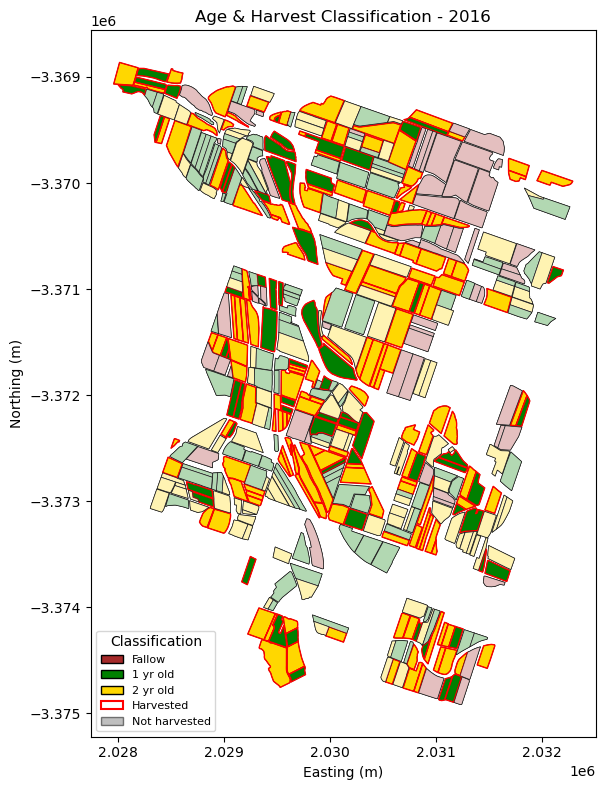

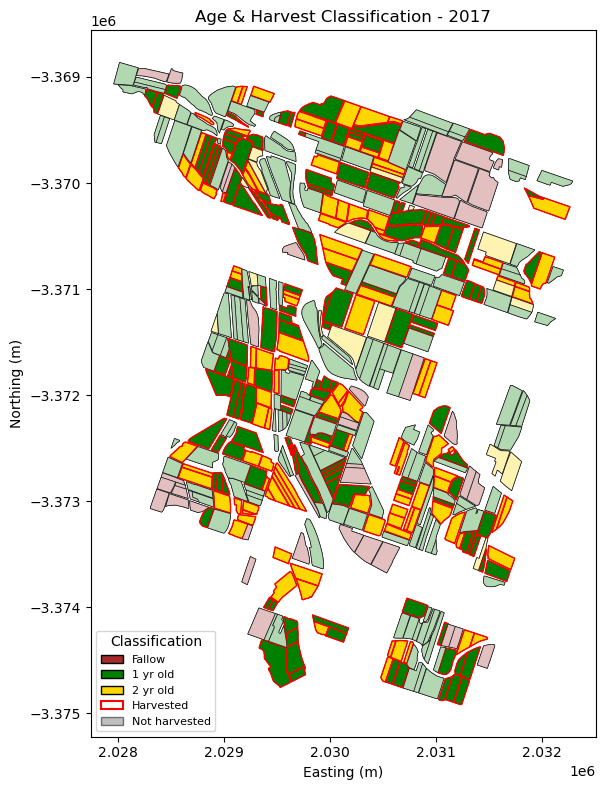

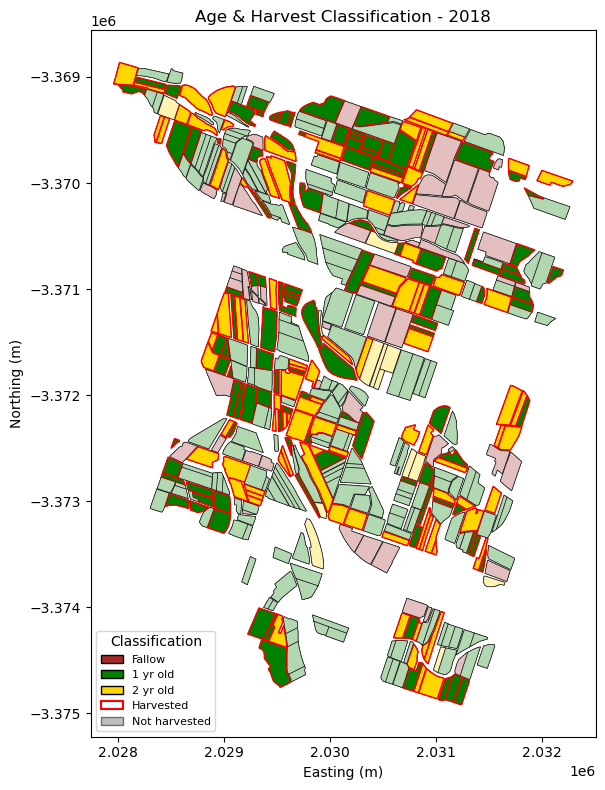

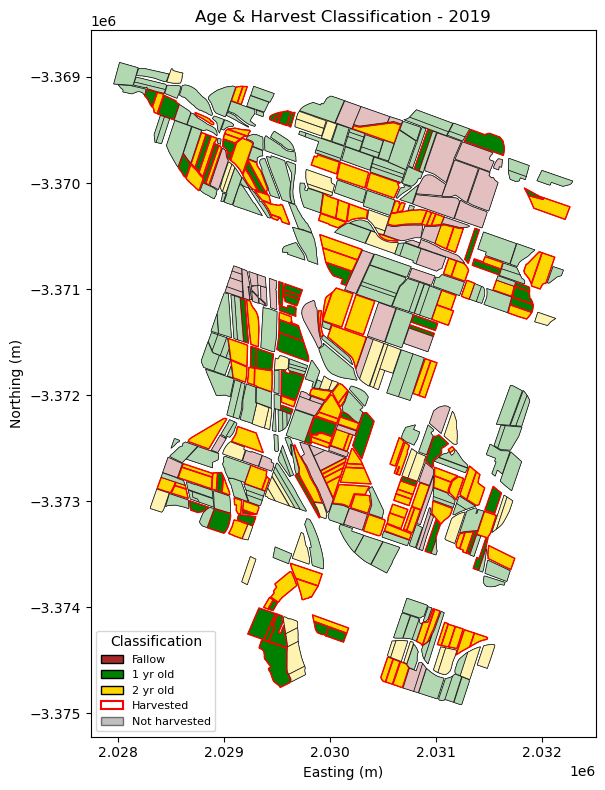

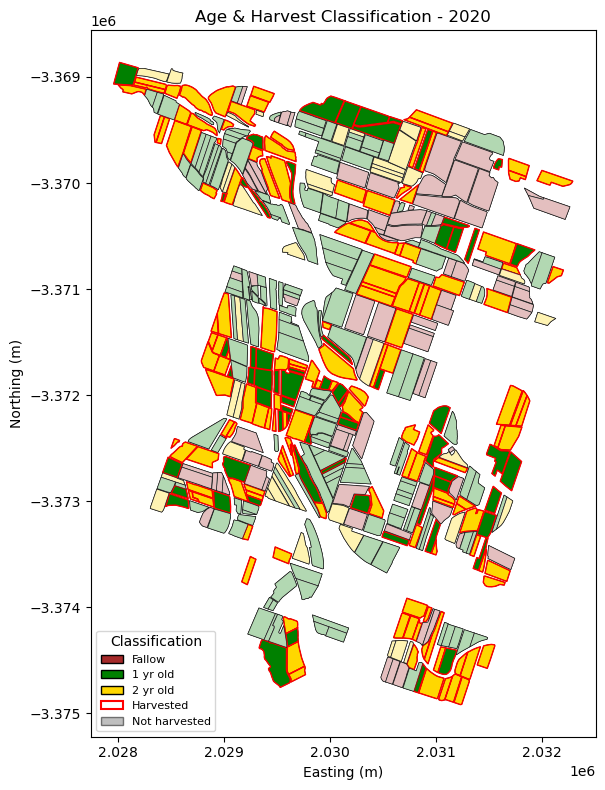

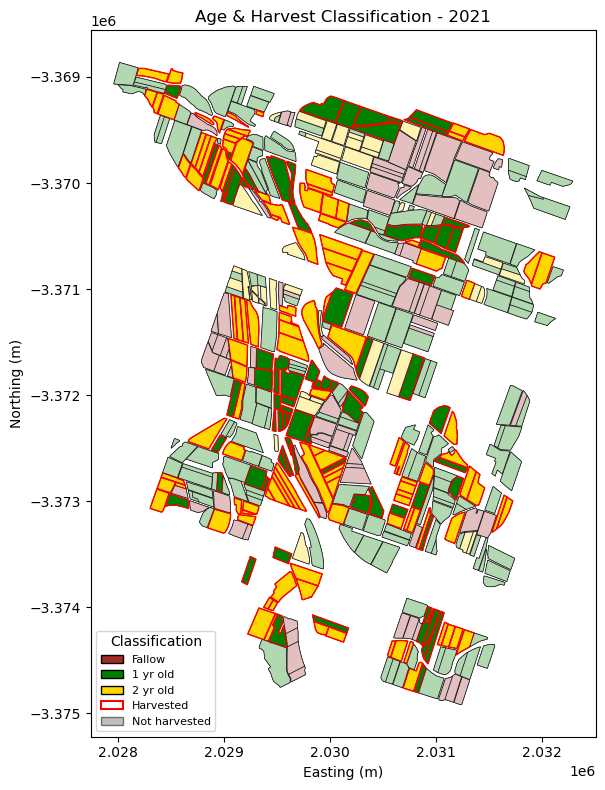

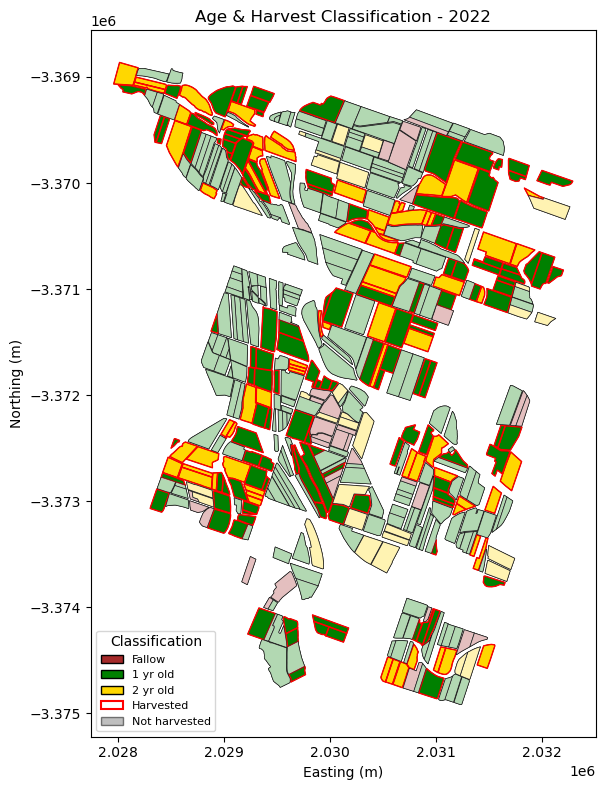

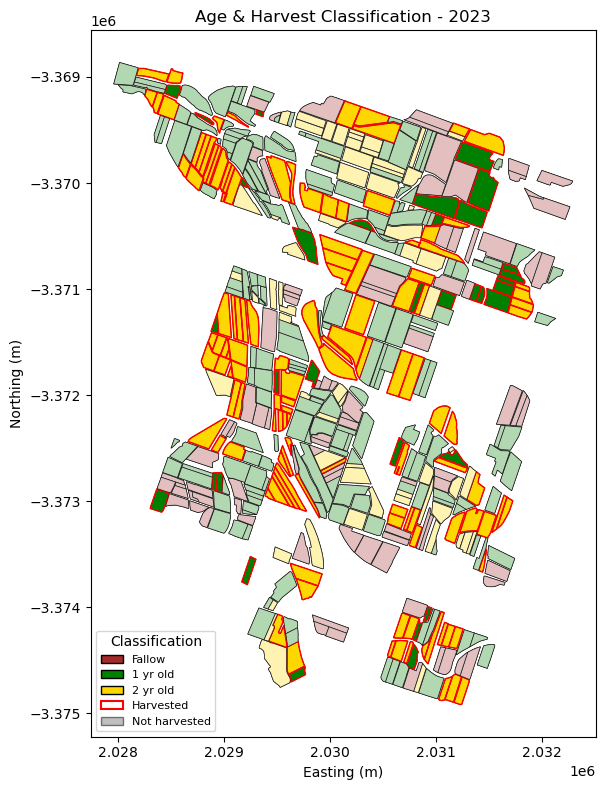

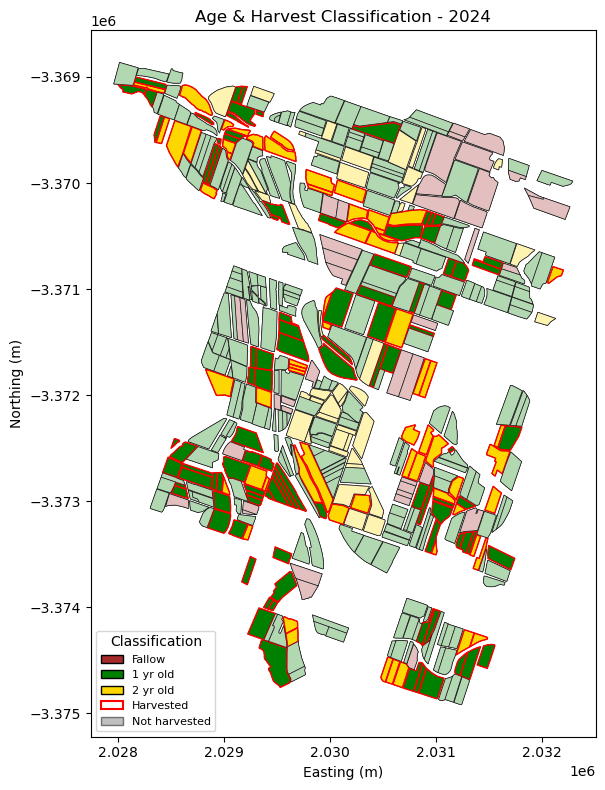

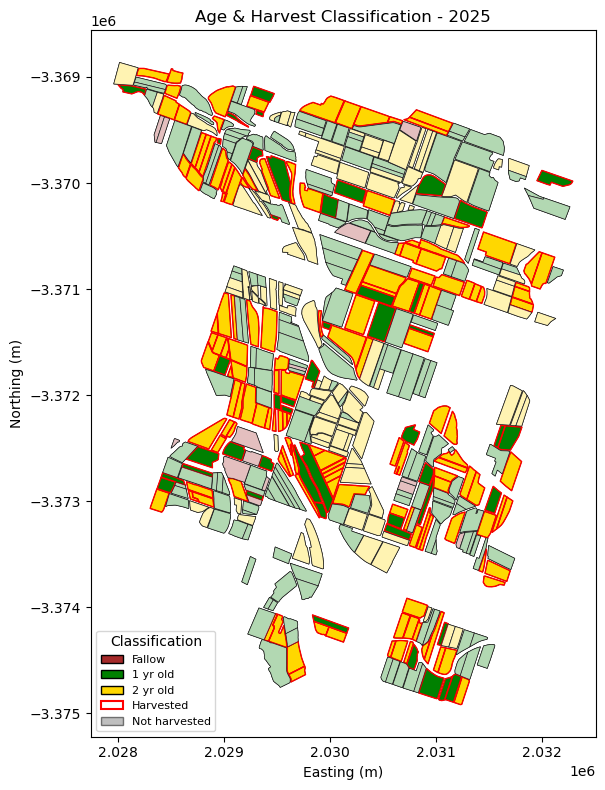

In [24]:
for year in years:
    plot_output(gdf, year)
    

In [12]:
# Area of each paddock in hectares
gdf['area_ha'] = gdf.geometry.area / 10_000

years = range(2016, 2026)

stats = pd.concat([
    pd.DataFrame({
        'year': year,
        'age': gdf[f'AGE_{year}'].values,
        'harvested': gdf[f'HARVESTED_{year}'].values,
        'area_ha': gdf['area_ha'].values
    })
    for year in years
], ignore_index=True)

# Exclude paddocks aged 0 and those not harvested
harvested_stats = stats[
    (stats['harvested'] == True) &
    (stats['age'] > 0)
]

annual_stats = (
    harvested_stats
    .groupby(['year', 'age'])
    .agg(
        paddock_count=('harvested', 'size'),
        area_ha=('area_ha', 'sum')
    )
    .reset_index()
)

print(annual_stats)

    year  age  paddock_count     area_ha
0   2016    1             67  117.677807
1   2016    2            154  305.815007
2   2017    1            140  247.830057
3   2017    2            117  200.603519
4   2018    1            119  206.466499
5   2018    2             97  197.828543
6   2019    1             58   97.719874
7   2019    2            133  246.448746
8   2020    1             65  121.469828
9   2020    2            142  278.618416
10  2021    1             78  143.776354
11  2021    2            118  220.485996
12  2022    1            133  263.469918
13  2022    2             75  158.061849
14  2023    1             33   60.560651
15  2023    2            124  253.400440
16  2024    1             99  184.986221
17  2024    2             63  119.287404
18  2025    1             47   92.297573
19  2025    2            145  284.770442


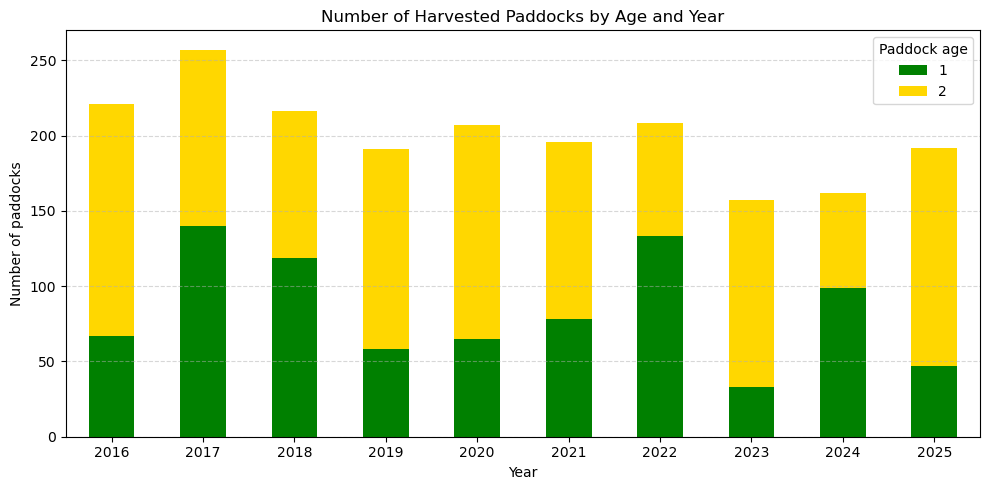

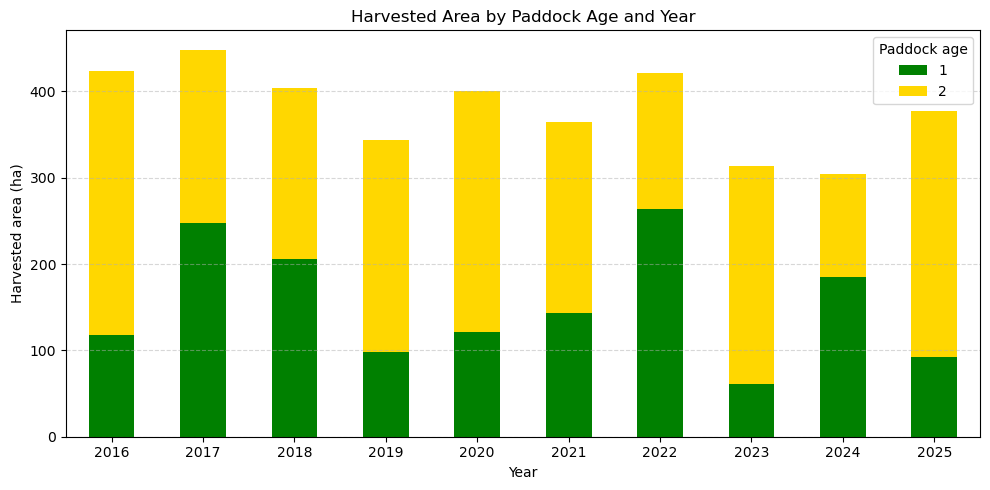

In [15]:

# Pivot data so each age is a separate series
paddock_counts = annual_stats.pivot(
    index='year',
    columns='age',
    values='paddock_count',
).fillna(0)

harvested_area = annual_stats.pivot(
    index='year',
    columns='age',
    values='area_ha'
).fillna(0)

# Plot 1: Number of harvested paddocks
paddock_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color = ["green","gold"]
)

plt.xlabel('Year')
plt.ylabel('Number of paddocks')
plt.title('Number of Harvested Paddocks by Age and Year')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Paddock age')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('Results/num_paddocks_harvested.png')
plt.show()


# Plot 2: Total harvested area
harvested_area.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color = ["green","gold"]
)

plt.xlabel('Year')
plt.ylabel('Harvested area (ha)')
plt.title('Harvested Area by Paddock Age and Year')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Paddock age')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('Results/harvested_area.png')
plt.show()

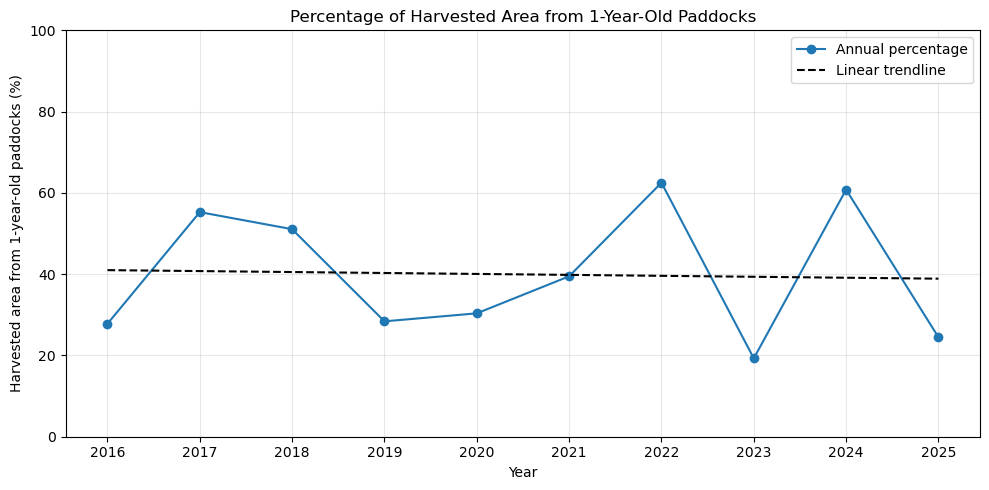

Trend: -0.23 percentage points per year
R²: 0.002


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Total area harvested each year, across all ages
total_area = harvested_stats.groupby('year')['area_ha'].sum()

# Area harvested from 1-year-old paddocks
area_1yr = (
    harvested_stats[harvested_stats['age'] == 1]
    .groupby('year')['area_ha']
    .sum()
)

# Percentage of harvested area from 1-year-old paddocks
pct_1yr = (area_1yr / total_area * 100).fillna(0)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(pct_1yr.index, pct_1yr.values, marker='o', label='Annual percentage')

# Linear trendline
x = pct_1yr.index.to_numpy(dtype=float)
y = pct_1yr.values

slope, intercept = np.polyfit(x, y, 1)
trendline = slope * x + intercept

plt.plot(
    x, trendline,
    linestyle='--',
    color='black',
    label='Linear trendline'
)

plt.xlabel('Year')
plt.ylabel('Harvested area from 1-year-old paddocks (%)')
plt.title('Percentage of Harvested Area from 1-Year-Old Paddocks')
plt.xticks(range(2016, 2026))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig('Results/percentage_of_harvested_area_1yrold.png', dpi=300)
plt.show()

y_pred = slope * x + intercept
r_squared = 1 - np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)

print(f"Trend: {slope:.2f} percentage points per year")
print(f"R²: {r_squared:.3f}")